# 사전과제 1117 추천시스템

# Part 1
# 1. 추천시스템 기초
## 1. 추천시스템이란?
- 사용자의 행동 기록과 아이템 정보 -> 사용자가 좋아할 만한 아이템을 *예측해서 골라 주는 시스템*
- 왜 필요할까?
     - 고객 : 찾는 시간과 노력이 줄어들며 몰랐던 취향의 아이템을 발견할 수 있다. (추천)
     - 기업 입장 : 이용 시간, 구매 전환, 재방문을 늘리고 비인기 아이템을 노출할 수 있다.

### 1. 사용되는 데이터의 종류와 특징
<선호 정보를 얻느냐에 따라 데이터가 나뉜다>
1. 명시적 데이터 : *고객들에 의해 입력된, 직접적 데이터*
     - 별점 좋아요 리뷰
     - 장점 : 비교가 분명해서 사용자의 취향을 정확히 반영
     - 단점 : 평가를 남기는 사람이 적고, 남겨도 일부만 남기게 된다. (명백한 데이터를 얻기 힘들다), 취향은 변한다, 점수의 기준이 주관적이다.
2. 암시적 데이터 : *고객들의 행동 기반으로 수집된, 간접적 데이터*
     - 장점 : 사용자가 입력 안해도 대량으로 쌓여서 얻기 쉽다
     - 단점 : 행동이 곧 선호라고 단정 못함 (잘못 클릭, 선물로 구매, 아이템을 아직 못 봤을 수도)(행동이 없다고 싫다는 건 아님))
     - 암시적 데이터가 더 많다 -> 섞어쓰는 경우가 대부분

### 2. 추천 시스템의 분류
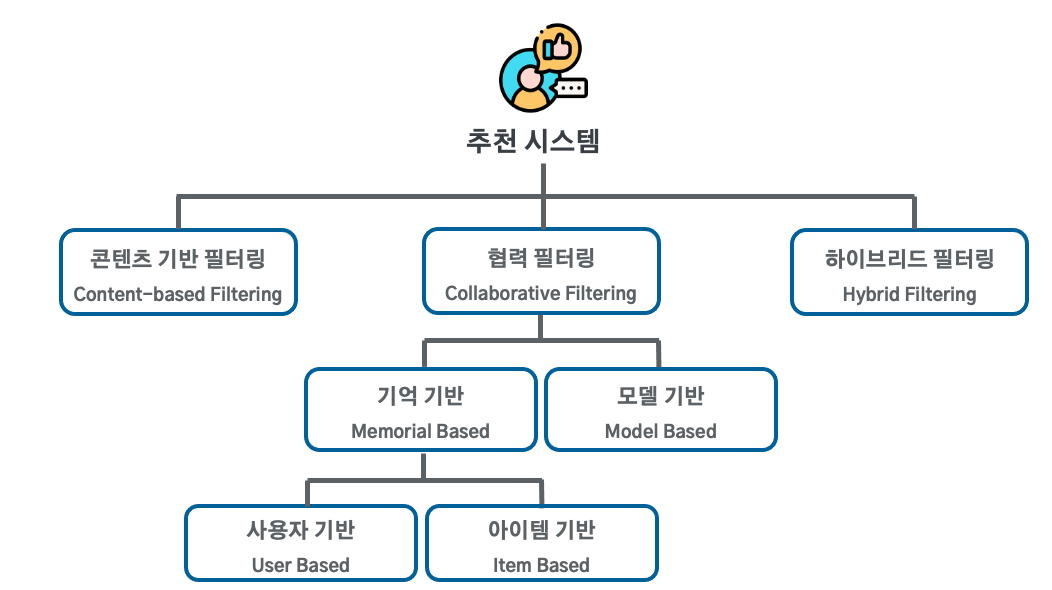
<무엇을 근거로 추천하는가>
- 1. **내용 기반 필터링** : 아이템 유사도를 근거로
     - SF 영화 자주 봄 => 다른 SF 영화 추천
- 2. **협업 필터링** : 다수 사용자 행동 패턴을 근거로
     - 취향이 비슷한 두 사람 -> 한 사람이 좋아한 아이템을 다른 사람도 좋아할 가능성이 높다고 봄
     - *사용자 기반* : 유사한 취향의 사용자가 선호한 아이템
     - *아이템 기반* : 사용자가 선호안 아이템과 유사한 아이템
- 3. **하이브리드** : 두 시스템 조합
     - 추천화 시스템 알고리즘을 조합 (2가지 이상 다양한 종류의)
     - 1,2번의 단점들을 보완
     - 예시 ) 오늘 개봉한 영화는 처음엔 협업 필터링 -> 평점이 쌓이면 내용 기반 추천

## 2.  내용 기반 필터링
핵심 흐름 : 아이템을 숫자화 -> 사용자 프로필 생성 -> 유사도 계산 -> 점수가 높은 아이템 추천
### 1. 사용자 프로필
: 사용자가 어떤 특성을 좋아하는지 정리한 정보

<사용되는 데이터>
1. 직접 지정형 : 사용자가 자신의 취향을 직접 알려줌 (좋아하는 장르, 아티스트)
2. 간접 지정형 : 사용자의 과거 행동 이력에서 취향 추론 (히어로 영화 선호 -> 스파이더맨 추천)
- 사용자 프로필 획득 방식
     - 1. 사용자가 가지고 있는 *아이템 특성 가중치의 평균값 활용*
     - 2. 설문, 키워드 입력 평가 등으로 *사용자 기호 파악* (명시적/암시적 피드백)
     - 3. 유저의 평가를 바탕으로 *분류 문제 해결* : 기존 평가를 정답 라벨로 두고 새 아이템에 어떤 평가를 줄지 예측
- 좋은 프로필일수록 추천 시스템의 정확도와 만족도가 높아짐

### 2. 유사도
: 두 대상이 얼마나 비슷한지 나타낸 수치
- 아이템 정보(텍스트 이미지) => 숫자 벡터로 변환 => 유사도 계산
- 사용자와 아이템을 *같은 기준*으로 표현해야 비교 가능
- 사용자가 선호하는 아이템을 비교해서 *유사도가 높은 아이템 선별*

### 3. TF - IDF 
- 중요하지 않은 단어가 자주 등장하면 중요한 단어로 취급되는 문제점 => TF-IDF로 해결 
- 특정 문서에는 자주 나오고 다른 문서에서는 드문 단어 = 높은 값
- *TF* : 단어 빈도 (특정 문서에 자주 나오면 커짐) / *IDF* : 역문서 빈도 (단어가 등장한 문서가 많을수록 작아짐)

### 4. 내용 기반 필터링의 장단점
- 장점
     - 콜드 스타트 문제 해결 -> 속성만 있으면 신규 아이템도 추천 가능
     - 다른 사용자 데이터가 필요 없음
     - 추천 이유를 설명하기 용이
- 단점
     - 속성 정보가 부족하거나 품질이 낮으면 정확도가 떨어짐
     - 비슷한 것만 계속 추천
     - 기록 없는 신규 사용자는 어려움 (사용자 콜드 스타트)
- **cold start** : 충분한 정보가 수집되지 않아서 적절한 제품을 못 추천해준다.
    - 아이템 : 새 아이템 평가 없음 -> 내용 기반으로 해결 가능
    - 사용자 : 사용자 기록 없음 -> 내용 기반으로도 어려움





# 3. 협업 필터링
가정 : 과거 비슷한 선호도 가진 사용자 -> 앞으로도 비슷한 선호도 갖는다.

## 1. 메모리 기반 협업 필터링
- 시스템에 저장된 사용자 : 평점 그대로 꺼내서 새로운 아이템 평점을 예측
- *이웃* (비슷한 사용자나 아이템) -> *이웃기반협업필터링*

<접근법>
1. 사용자 기반 : 이웃의 평점을 이용해 내 평점 예측
     - 이웃 = 유사도가 높은 사용자 TOP N
     - 이웃의 유사도를 가중평가해서 내가 아직 평가하지 않은 아이템 평점 예측 -> 평점 높은 아이템 추천
2. 아이템 기반 : 내가 평가한 아이템들이랑 평점 패턴이 비슷한 아이템 추천
     - 사용자가 그 아이템을 선호? 비선호? 로 유사도 판단.
     - 아이템끼리의 관계는 상대적으로 덜 변하기에 *미리 계산해두고 재사용하기 좋음*
- 왜 사용자 수가 많으면 *아이템 기반이 유리?* : 두 아이템을 함께 평가한 사용자가 많을 가능성이 높다.
- 새로운 추천 필요한 플랫폼 : user based / 정확하고 안정적인 추천 필요한 대형 플랫폼 : item based

### 2. 메모리 기반 협업 필터링 한계
1. 희소 행렬 문제 : 주어진 평점, 선호도 데이터가 적을 때 성능이 저하되는 문제
     - 실제로 대부분 칸이 비어있음
     - 유사도의 신뢰성이 떨어짐, 예측 자체가 어려움
     - *모델 기반 협업 필터링 CF* 이용
2. 콜드 스타트 문제 : 데이터가 부족해서 적절한 추천을 못함
     - 1) 신규 아이템 - 아무도 평가하지 않아서 추천 후보에 못 올라감
     - 2) 신규 이용자 - 평가 기록이 없어 비슷한 이웃을 찾을 수 없음
     - 해결 방법 : 자신이 직접 좋아하는 것 지정하도록 하기, 내용 기반 필터링을 함께 쓰는 하이브리드 방식 사용, 임베딩 평균으로 임시 표현, 인구통계학적 정보를 사용해서 추정
3. 확장성 문제 : 아이템과 사용자가 늘어날 수록 계산량이 커짐 -> 그만큼 추천 품질도 떨어짐
     - *KNN 협업 필터링* 이용 : 유사도가 높은 k명만 골라서 ㅇㅖ측

### 3. 모델 기반 협업 필터링
- 관측된 평점 데이터로 예측 모델 학습하고, 관측되지 않은 평점 예측
     - 메모리 기반 : 추천 필요할 때마다 직접 비교
     - 모델 기반 : 데이터를 압축된 모델로 요약해두고, 추천은 이 모델만으로 수행
- 단계
     - 1. 학습 단계 : 이미 존재하는 평점 잘 설명하는 파라미터 찾기
     - 2. 예측 단계 : 학습된 파라미터로 비어 있는 칸 평점 계산
- 등장 배경 : 메모리 기반 협업 필터링은 평점 사이의 유사도에만 의존해서 *희소성과 확장성 문제에 취약* => 모델 기반은 잠재된 패턴을 학습해서 빈캄 추정하고 계산을 가볍게 해줌

- **잠재 요인** :평점에는 안 드러나지만, 사용자와 아이템 사이 관계를 결정짓는 *숨은 특성* 
- **latent factor model** : 사용자와 아이템을 같은 잠재 공간 위의 벡터로 나타내서 두 벡터 관계로 평점 설명, 축은 학습 과정에서 결정됨
     - 평점 행렬 = 사용자-잠재요인 행렬 / 아이템-잠재 요인 행렬
     - 행렬 분해 : 큰 평점 행렬 = 작은 행렬 두 개의 곱으로 쪼갬 / 예측 평점은 두 벡터의 내적






# Part 2. 딥러닝 기반 추천 시스템

## 1. VAE 기반 협업 필터링
- 사용자의 상호작용 기록을 신경망으로 *확률분포*로 압축 => 다시 복원하면서 아직 보지 않은 아이템 선호 예측
- 구조 : 
     - 인코더 : 사용자 상호작용 벡터를 받아서 잠재 공간의 평균과 표준편차로 변환 -> 취향을 분포로 추정
     - 샘플링 : 인코더가 추정한 분포에서 잠재 벡터를 무작위로 뽑아 디코더에 전달
     - 디코더 : 잠재벡터를 점수로 변화해서 선호 확률을 출력, 이 확률 순서로 아직 상호작용을 하지 않은 아이템 추천
- 장점: 불확실성을 반영하고 희소한 상호작용 데이터에서 강건하다.

### 1. MF의 한계와 딥러닝 등장
- MF 한계 : *요인끼리 얽히는 효과를 표현하기가 어렵다.* ,*점추정*을 하기에 기록이 적은 사용자 추정이 불안정해도 구분하지 못한다.
- 딥러닝의 해법 : 
     - 선형성 -> 비선형 활성화 함수 가진 신경망 
     - 불확실성 무시 -> 평균과 분산을 함께 출력
     => VAE 등장!

### 2. AE가 아닌 VAE인 이유는?
- 오토인코더 AE : 작은 벡터로 압축했다가 복원하는 신경망 모델
- 입력 복원에 필요한 핵심 정보만 남기도록, 입력 자체가 정답

- VAE : 점 하나가 아닌 **분포**로 표현하는 오토인코더 
     - 점 하나가 아니라 그 주변 분포를 사용해서 학습함
     - 기존 분포 쪽으로 당겨짐 (정규분포)

### 3. VAE 기반 CF의 작동 구조
- mult VAE는 사용자의 상호작용 기록을 분포로 요약하고 전체 아이템의 선호 확률을 복원해서 추천하는 구조

### 4. 목적 함수와 KL Divergence
- 목적함수 ELBO : 데이터가 나올 로그 확률 **하한**을 키우는 방식이다.
     - 복원항 (첫 항) 원래 입력을 최대한 비슷하게 복원
     - KL Divergence 항 (두 번째 항) 과적합을 막고 잠재 공간이 불규칙해지지 않도록 연속적으로 유지
- KL Divergence : 두 확률 분포가 얼마나 다른가? 
     - 중심에서 멀어지거나 지나치게 확신하거나 퍼지면 벌점이 커짐
     - VAE는 분포들이 중앙 근처에서 **연속적으로** 모임, KL divergence가 잠재공간을 정규 분포 근처로 압축해서 부드럽게 만든다. => 안정적 예측 가능

- VAE -CF의 주요 장점
     - 확률적 잠재 분포 모델링으로 불확실성을 반영한다. (노이즈의 영향도 줄임)
     - 희소한 상호작용 데이터에서도 안정성을 보임
     - 비선형성을 학습함

## 2. GNN 기반 사용자 선호 예측
- 관계 자체를 데이터로 보고 모델링할 수는 없을까??

## GNN
- 모티브 : 사용자들끼리는 서로 연결된 관계망을 형성한다는 점에서 모티브를 얻었다.
- 그래프 :노드와 노드를 잇는 선 엣지를 모아서 구성한 자료 구조이다.
     - 사용자 -팔로우- 사용자
     - 왜 사용할까?
          - 추상적 개념, 관계 상호작용 등을 다루기 적합
          - 비유클리드 공간을 노드와 엣지로 표현하고 학습 (격자구조가 없는 공간)

### GNN의 구조
1. 노드와 엣지 정의하고 각 노드에 임베딩 부요
2. 각 노드가 이웃 노드로부터 정보를 받아서 전달 (메세지 패싱)
     - 메세지 생성 : 각 이웃 노드가 자신의 임베딩으로 전할 메세지 생성
     - 집계 : 타깃 노드가 메시지를 합침
     - 갱신 : 집계 결과에 이전 임베딩을 결합해서 새 임베딩 생성
3. 출력
* 핵심 아이디어 = 내 이웃노드의 정보를 나에게 전달하고 요약

### GNN 프로세스
- 메세지 패싱 수행 = 자신의 이웃 노드들이 정보 (잠재 요인) 수집해서 자신의 은닉 상태를 임베딩 -> 반복해서 이웃들 취향까지 반영한 최종 임베딩
<Br>

1. 그래프 구조 생성
- 노드와 엣지 정의하고 노드에 피처 부여
2. 메세지 패싱
- GNN 하나의 레이어는 '메세지 생성-집계-갱신' 단계로 이루어진다.
- 타깃노드= 임베딩 갱신 대상 노드, 모든 노드가 한 번씩 타깃 노드가 된다.
     - 1) 메시지 생성  : 이웃에게 보낼 정보 생성
     - 2) 집계 : 메세지 생성 후 여러 이웃 노드에서 받은 메세지를 하나의 벡터로 통합
     - 3) 갱신 : 집계된 이웃 정보와 자신의 이전 상태를 결합해서 새로운 임베딩을 계산 -> 반복하면서 멀리있는 이웃 정보까지 반영

### light GCN
- GNN 아키텍처들의 차이는 메세지를 *어떻게 만드는가와 합치는가*로 결정된다

- 주요 아키텍처
     - GCN : 그래프 위해서 convolution 연산 수행해서 이웃 정보 집계
     - GRN : RNN+GNN, 시간에 따라 노드 업데이트 -> 동적 변화 포착 가능
     - GAT : 이웃 노드 간 중요도를 학습해서 가중 평균을 낸다 -> 타겟 노드의 이웃 노드 중 가장 중요한 노드에 가중치
     - Graph SAGE : 대규모 그래프에 대해 샘플링 기반으로 학습
=> GCN 계열이 가장 잘 쓰인다 

- light GCN : NGCF는 레이어마다 가중치 행렬을 곱하고 비선형 활성화 함수를 적용했다면 이 light GCN은 두 연산을 제거하고 추천의 핵심인 사용자-아이템 간 연결 관계만 전달하도록 단순화시켰다.

- GNN에서 제거한 구성요소
     - 1. 특징 변환 제거
     - 2. 비선형 활성화 함수 제거
     - => 정규화된 이웃 임베딩의 합과 레이어의 결합만으로 가볍게 구성

### GNN 활용 사례
- pinterest -> 이미지 선택하면 유사 이미지 보여줌, 홈 화면에 사용자 선호 이미지

## 6. 장단점
- 장점
     - 1. 고차원 협업 시그널 포착
     - 2. 정형화되지 않은 데이터 학습이 가능
    - 3. 콜드 스타트 문제 완화에 효과적
- 단점
     - 1. 과평탄화 문제
     - 2. 과압축 문제
     - 3. 계산의 복잡도 증가
     - 4. 순서 반영의 어려움



# 3. transformer 기반 추천 시스템

## 1. 기존 추천 시스템의 순차적 한계
- CF의 순차적 한계
     - 순서 무시, 문맥 부족, 예측 한계
- GNN의 순차적 한계
     - 지역적 정보 전파 한계
     - 장기 의존성 문제

## 트랜스포머 : 사용자 행동을 순서대로
- 같은 사용자도 세션마다 탐색하는 상품군이 다르므로 장기적 취향보다 '최근 행동 순서와 조합에 큰 영향 받는다.
- 활용 방식
     - 1. 셀프어텐션 / 문맥에 따라 달라지는 동일 아이템의 의미
     - 2. long range dependency / 시간, 순서를 뛰어넘는 핵심 의도 포착
## 3. self attention
- 두 아이템 사이의 장기 의존성 문제 해결
- 동작 원리 : Q K V
      - 연산 : Q와 K 내적해서 관련성 점수 구한다 -> softmax로 점수 합이 1인 가중치로 바꾸고 -> 각 아이템의 value에 가중치를 곱해서 더한다.
      - 관련성에 따라 정보 반영 비율을 다르게 적용하는 것이다.

## 4. transformer 기반 주요 추천 시스템 모델
- SASRec : 단방향 어텐션으로 과거 정보만 활용해서 다음 아이템 예측
     - 과거 아이템만 참조 가능
     - 특징 : 적응적 집중, 빠른 학습
     - 단점 : 계산량, 단방향성
- BERT4Rec : 양방향 어텐션으로 과거와 미래 정보 모두 활용, 가려진 아이템 예측
     - 시퀀스 일부를 mask로 가리고 가려진 위치가 과거와 미래의 모든 아이템 참조
     - 목표 : 가려진 아이템 예측
     - 특징 : 1. 양방향 문맥, 2. 데이터 활용
- 선택 기준
     - 상호작용이 많고 다음 행동 예측이 목적 : SASRec
     - 상호작용이 적고 시퀀스가 짧음 : 상황에 따라 다름
     - 행동 순서가 느슨 (동시 담기 가능) : BERT4REC

# 4. 오늘날의 추천 시스템
## 1. LLM의 시대
- 추천을 점수 계산이 아닌 *문장*으로 출력 (서술형 추천 가능)
     - 1. 대화형 추천 가능
     - 2. zero shot 추천 가능 (텍스트 설명만으로 추천)
- LLM 추천 적용 방식
     - 1. p5 : 텍스트 프롬프트 -> 텍스트 답변 / 많은 컴퓨팅 자원과 시간 필요
     - 2. TALLRec : 학습 비용 줄이기 위해 선호? yes/no 형식 지시문으로 튜닝

## 2. 인기 편향과 XAI 문제
1. 인기 편향 - 소수의 인기 아이템이 추천을 독점
     - 데이터 불균형
     - 모델의 편향 강화
     - rich get richer : 격차가 커짐
     - 예 ) 넷플릭스 
2. 설명 가능성 (XAI) :왜 추천했는지 설명 가능한가? - 나에게 맞춤으로 추천한 이유가 적합하다는 근거가 없다.

## 3. 콜드 스타트를 고려한 추천 시스템 도입
- 비용 문제로 딥러닝 전면 도입이 어려움 (GPU, 서버비용, 지속 비용)
- 사용하는 구조
     - 1. 후보군 생성 (선형 모델로 수백만개를 수백개 후보로 축소)
     - 2. 순위 매기기 ( 수백 개의 후보를 정교하게 정렬해서 상위 수십 개를 노출한다. 정확도도 높고 복잡한 패턴이 있음)
     
